# RQ1 — Is annotator disagreement on colonial-redress events systematic, and where does it concentrate?

This notebook reproduces every number in **§3.1 (RQ1)** of the paper, together with **Table 1** (dataset
overview), the paragraph on retrospective hesitancy ratings in **§2.1**, and the figure *Contestation by
stratum / Recurring label boundaries*. All code is in the cells below; the only inputs are the Label Studio
exports in `ls_real/`.

Run the cells from top to bottom (*Run All*). Requirements: `numpy`, `pandas`, `scipy`, `statsmodels`,
`matplotlib`. Running the whole notebook takes about a minute.

**Contents**
0. From Label Studio exports to readings
1. Table 1 and the retrospective hesitancy ratings (§2.1)
2. Check 1 — stratification by category type
3. Check 2 — recurrence on the same category boundaries (HHI)
4. Check 3 — hesitant annotators name the other annotator's reading
5. Check 4 — hesitancy predicts divergence
6. Figure: contestation by stratum and recurring label boundaries
7. Recap

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')

# The data lives in ls_real/ at the root of the redress_paper folder. Walk up from the
# notebook's folder until we find it, and work from there so that all paths are relative.
REPO = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(REPO, 'ls_real')):
    parent = os.path.dirname(REPO)
    if parent == REPO:
        raise FileNotFoundError('Run this notebook from inside the redress_paper folder (ls_real/ not found).')
    REPO = parent
os.chdir(REPO)
D = 'ls_real'
FIG_DIR = os.path.join('rq_notebooks', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 60)
print('working directory:', REPO)

working directory: c:\Users\tessd\RedressHub_paper


## Step 0 — from Label Studio exports to *readings*

The double-annotated dataset is stored as pairs of Label Studio exports in `ls_real/`. Each pair
covers the same texts, annotated independently by two annotators (a *pool*):

| pool | annotator A | annotator B | pair |
|---|---|---|---|
| `iaa` | Cira (re-annotation) | Elke (re-annotation) | domain experts |
| `cira_solo` | Cira (hesitancy added retrospectively) | Elke (in the moment) | domain experts |
| `elke_solo` | Elke (hesitancy added retrospectively) | Cira (in the moment) | domain experts |
| `iaa_nl` | Elke (re-annotation) | trained annotator A3 | expert × trained |
| `elke_solo_nl` | Elke (hesitancy added retrospectively) | trained annotator A3 | expert × trained |

The code below turns every labelled span into one **reading** (paper, §1.1): one annotator's label on
one span. For each reading we look for the partner annotator's spans that overlap it by at least one
character:

* `other_label` — the label of the partner's span with the largest overlap (empty if the partner marked
  nothing there: a *one-sided* span);
* `divergent` — 1 if none of the overlapping partner spans has the same label;
* `friction` — 1 if the reading is divergent **or** the annotator rated it *somewhat* or *very hesitant*;
* `ftype` — `agreed` (no friction), `contested` (friction, and the partner marked the passage too) or
  `detection` (only this annotator marked the passage).

Three spans were accidentally labelled twice (same span, same label) by the same annotator; we keep one
copy of each (`dedup=True`). Two other spans deliberately carry two different labels (an event type and
`Organisation`); both readings are kept. One Dutch article was annotated twice, in two different pools;
we keep one copy (`EXCLUDE_TEXTS`, see the duplicate check in the RQ1 notebook). The three vaguer *Time*
labels are left out of the analysis, as in the paper.

**No article texts.** The articles remain under their publishers' copyright, so the exports contain only
character offsets, no text. `ls_real/texts.csv` lists, for every text, its source URL, source, language,
length and a SHA-256 checksum of the exact text that was annotated. None of the analyses needs the texts
themselves. If the full texts are available locally (project members: see the README), `load_texts()`
returns them, and the notebooks then also show the span texts and re-run the duplicate check from scratch.

In [2]:
RATING = {'certain': 0, 'mostly certain': 1, 'somewhat hesitant': 2, 'very hesitant': 3}
NAME = {1182: 'Cira', 1188: 'Elke', 644: 'A3'}             # Label Studio user id -> annotator
POOLS = [  # pool, export of annotator A, export of annotator B (same texts), annotator pair
    ('iaa', 'export_reann_cira.json', 'export_reann_elke.json', 'expert-expert'),
    ('cira_solo', 'export_hesretro_cira.json', 'export_cross_elke.json', 'expert-expert'),
    ('elke_solo', 'export_hesretro_elke.json', 'export_cross_cira.json', 'expert-expert'),
    ('iaa_nl', 'export_reann_elke_nl.json', 'export_reann_a3.json', 'expert-trained'),
    ('elke_solo_nl', 'export_hesretro_elke_nl.json', 'export_cross_a3.json', 'expert-trained'),
]
# descriptive labels; every other label is normative
STRATUM = {'Organisation': 'descriptive', 'Time_absolute': 'descriptive',
           'Books': 'descriptive', 'Location': 'descriptive'}
DROP = {'Time_relative', 'Time_range', 'Time_vague'}         # left out of the analysis
KEYS = ['text_key', 'annotator', 'start', 'end']              # identifies one reading
# The same Dutch article was annotated twice, once in the iaa_nl pool and once in the elke_solo_nl pool
# (see the duplicate check in the RQ1 notebook). We keep the iaa_nl copy, in which both annotators rated
# their hesitancy while annotating, and leave out the other copy.
EXCLUDE_TEXTS = {'elke_solo_nl:335223'}
# one row per text: source URL, source, language, length and SHA-256 checksum of the annotated text
TEXT_META = pd.read_csv(os.path.join(D, 'texts.csv')).set_index('text_key')


def load_texts():
    """The full annotated texts, if available locally (ls_real/texts_full.json, or exports that still contain
    the texts); otherwise None. Each text is checked against its checksum in texts.csv."""
    import hashlib
    path = os.path.join(D, 'texts_full.json')
    texts = json.load(open(path, encoding='utf-8')) if os.path.exists(path) else {}
    if not texts:
        for pool, fa, fb, pair in POOLS:
            for f in (fa, fb):
                for t in json.load(open(os.path.join(D, f), encoding='utf-8')):
                    if 'text' in t['data']:
                        texts[f'{pool}:{t["data"]["orig_task_id"]}'] = t['data']['text']
    for k, v in texts.items():
        assert hashlib.sha256(v.encode('utf-8')).hexdigest() == TEXT_META.loc[k, 'sha256'], f'{k}: checksum mismatch'
    return texts or None


def parse(task, drop, collapse):
    """Spans and per-span choices (hesitancy, alternative label, source of doubt) of one annotation."""
    canon = lambda label: collapse.get(label, label)
    ann = [a for a in task['annotations'] if not a.get('was_cancelled')][0]
    spans = [dict(id=r['id'], start=r['value']['start'], end=r['value']['end'], label=canon(r['value']['labels'][0]))
             for r in ann['result'] if r.get('type') == 'labels' and canon(r['value']['labels'][0]) not in drop]
    choices = {'hesitancy': {}, 'alt_label': {}, 'doubt_source': {}}
    for r in ann['result']:
        if r.get('type') == 'choices' and r.get('from_name') in choices:
            v = r['value']['choices'][0]
            if r['from_name'] == 'alt_label':
                v = canon(v)
                if v in drop:
                    continue
            choices[r['from_name']][r['id']] = v
    return ann['completed_by'], spans, choices


def overlap(a, b):
    """Two spans overlap if they share at least one character."""
    return a['start'] < b['end'] and b['start'] < a['end']


def rows_for(task, other_task, pool, pair, drop, collapse, stratum):
    """One row (reading) per span of `task`, compared with the partner's annotation `other_task`."""
    user, spans, choices = parse(task, drop, collapse)
    _, other_spans, _ = parse(other_task, drop, collapse)
    text_key = f'{pool}:{task["data"]["orig_task_id"]}'
    mode = 'retrospective' if task['data'].get('arm') == 'retrospective' else 'in-the-moment'
    out = []
    for s in spans:
        cands = [o for o in other_spans if overlap(s, o)]
        matched = any(o['label'] == s['label'] for o in cands)
        other_label = (max(cands, key=lambda o: min(s['end'], o['end']) - max(s['start'], o['start']))['label']
                       if cands else None)
        out.append(dict(pool=pool, pair=pair, text_key=text_key,
                        annotator=NAME.get(user, user), mode=mode, lang=TEXT_META.loc[text_key, 'lang'],
                        start=s['start'], end=s['end'], label=s['label'],
                        stratum=stratum.get(s['label'], 'normative'),
                        hesitancy=RATING[choices['hesitancy'][s['id']]],
                        alt_label=choices['alt_label'].get(s['id']),
                        doubt_source=choices['doubt_source'].get(s['id']),
                        other_label=other_label, divergent=int(not matched)))
    return out


def build_readings(drop=DROP, collapse=None, stratum=STRATUM, dedup=True, exclude=EXCLUDE_TEXTS):
    collapse = collapse or {}
    rows = []
    for pool, fa, fb, pair in POOLS:
        a = {t['data']['orig_task_id']: t for t in json.load(open(os.path.join(D, fa), encoding='utf-8'))}
        b = {t['data']['orig_task_id']: t for t in json.load(open(os.path.join(D, fb), encoding='utf-8'))}
        assert set(a) == set(b), f'{pool}: the two exports do not cover the same texts'
        for k in a:
            if f'{pool}:{k}' in exclude:
                continue
            rows += rows_for(a[k], b[k], pool, pair, drop, collapse, stratum)
            rows += rows_for(b[k], a[k], pool, pair, drop, collapse, stratum)
    df = pd.DataFrame(rows)
    df['friction'] = ((df.divergent == 1) | (df.hesitancy >= 2)).astype(int)
    if dedup:  # three spans were accidentally labelled twice (same span, same label) by the same annotator
        df = df.drop_duplicates(KEYS + ['label']).reset_index(drop=True)
    df['ftype'] = np.where(df.friction == 0, 'agreed', np.where(df.other_label.notna(), 'contested', 'detection'))
    # 'first' marks the readings of one (alphabetically first) annotator per text, so that each
    # label split is counted once rather than once per annotator
    who = df.groupby('text_key').annotator.agg(lambda s: sorted(set(s)))
    df['first'] = [a == who[k][0] for k, a in zip(df.text_key, df.annotator)]
    return df


def passages(frame):
    """Passage id per reading: readings whose spans overlap (directly or via a chain) share a passage."""
    pid = np.full(len(frame), -1)
    nxt = 0
    for _, g in frame.groupby('text_key'):
        idx = g.index.values
        s, e = g.start.values, g.end.values
        parent = list(range(len(idx)))
        def find(i):
            while parent[i] != i:
                parent[i] = parent[parent[i]]
                i = parent[i]
            return i
        for i in range(len(idx)):
            for j in range(i + 1, len(idx)):
                if s[i] < e[j] and s[j] < e[i]:
                    parent[find(i)] = find(j)
        roots = {}
        for i in range(len(idx)):
            r = find(i)
            if r not in roots:
                roots[r] = nxt
                nxt += 1
            pid[frame.index.get_loc(idx[i])] = roots[r]
    return pid

In [3]:
df = build_readings()
df['pid'] = passages(df)
print(f'{len(df)} readings in {df.text_key.nunique()} texts')
df[['pool', 'pair', 'text_key', 'annotator', 'label', 'stratum', 'hesitancy', 'other_label', 'divergent', 'ftype']].head(8)

1469 readings in 67 texts


,pool,pair,text_key,annotator,label,stratum,hesitancy,other_label,divergent,ftype
0,iaa,expert-expert,iaa:285647,Cira,Truth-seeking initiatives,normative,0,Truth-seeking initiatives,0,agreed
1,iaa,expert-expert,iaa:285647,Cira,Truth-seeking initiatives,normative,0,Truth-seeking initiatives,0,agreed
2,iaa,expert-expert,iaa:285647,Cira,Time_absolute,descriptive,0,None,1,detection
3,iaa,expert-expert,iaa:285647,Cira,Public acknowledgements,normative,0,Apologies,1,contested
4,iaa,expert-expert,iaa:285647,Cira,Organisation,descriptive,0,Organisation,0,agreed
5,iaa,expert-expert,iaa:285647,Cira,Time_absolute,descriptive,0,None,1,detection
6,iaa,expert-expert,iaa:285647,Cira,Time_absolute,descriptive,2,None,1,detection
7,iaa,expert-expert,iaa:285647,Cira,Truth-seeking initiatives,normative,2,Truth-seeking initiatives,0,contested


### The texts: sources and languages

`texts.csv` lists every annotated text with its source URL. The articles themselves are not part of this
repository (see Step 0). The table below counts the texts used in the analyses by source and language.

In [4]:
used = TEXT_META[TEXT_META.in_analysis]
print(f'{len(TEXT_META)} texts in the exports, {len(used)} used in the analyses')
used.groupby(['lang', 'source']).size().unstack(0, fill_value=0)

68 texts in the exports, 67 used in the analyses


lang,en,fr,nl
source,,,
africamuseum.be,8,7,0
archive.africalia.be,0,1,0
bozar.be,5,0,0
cec-ong.org,0,8,0
dewereldmorgen.be,0,0,4
justiceinfo.net,4,0,0
justicepaix.be,0,1,0
memoirecoloniale.com,0,3,0
mo.be,1,0,23


### Duplicate texts across pools

Each pool is checked for consistency (both exports cover the same texts), but the same article could also
end up in two different pools. We compare every pair of texts from different pools by their word overlap
(the share of the shorter text's distinct words that also occur in the longer one). One pair is the same
article: `iaa_nl:285645` and `elke_solo_nl:335223` (both link to the same URL in `texts.csv`). We keep the
`iaa_nl` copy, in which both annotators rated their hesitancy while annotating, and leave out the other
(`EXCLUDE_TEXTS` above). The other pairs with a high overlap are very short texts (about 550 characters)
whose words also occur in long articles; they are not duplicates.

The check needs the texts. Without them, the cell shows the stored result (`ls_real/duplicate_check.csv`);
with the texts available locally, it recomputes it and confirms that the two agree.

In [5]:
import re, itertools
stored = pd.read_csv(os.path.join(D, 'duplicate_check.csv'))
all_texts = load_texts()
if all_texts is None:
    print('Full texts not available: showing the stored duplicate check.')
    result = stored
else:
    words = {k: set(re.findall(r'\w+', v.lower())) for k, v in all_texts.items()}
    rows = []
    for a, b in itertools.combinations(sorted(all_texts), 2):
        if a.split(':')[0] != b.split(':')[0]:
            overlap_share = len(words[a] & words[b]) / max(1, min(len(words[a]), len(words[b])))
            if overlap_share > .6:
                rows.append({'text A': a, 'text B': b, 'word overlap': round(overlap_share, 3),
                             'characters A': len(all_texts[a]), 'characters B': len(all_texts[b])})
    result = pd.DataFrame(rows).sort_values('word overlap', ascending=False).reset_index(drop=True)
    assert result.equals(stored), 'recomputed duplicate check differs from ls_real/duplicate_check.csv'
    print('Duplicate check recomputed from the full texts; identical to the stored result.')
same_url = TEXT_META[TEXT_META.url.duplicated(keep=False)]
print(f'texts sharing a URL: {sorted(same_url.index)}; {df.text_key.nunique()} texts after leaving out {sorted(EXCLUDE_TEXTS)}')
result

Full texts not available: showing the stored duplicate check.
texts sharing a URL: ['elke_solo_nl:335223', 'iaa_nl:285645']; 67 texts after leaving out ['elke_solo_nl:335223']


,text A,text B,word overlap,characters A,characters B
0,elke_solo_nl:335223,iaa_nl:285645,0.998,18091,18424
1,cira_solo:335567,elke_solo:335320,0.651,548,16773
2,elke_solo_nl:335223,iaa_nl:285655,0.618,18091,554
3,cira_solo:335567,iaa:285651,0.603,548,20459
4,elke_solo_nl:335292,iaa_nl:285655,0.603,19707,554


## Step 1 — Table 1 and the retrospective hesitancy ratings

Table 1 counts **labelled spans** as annotated (including the three spans labelled twice by accident), and
the **contested normative readings** after removing those duplicates. Both leave out the second copy of
the duplicated article. A normative reading counts as contested
if the partner chose a different label for the overlapping span, or the annotator was hesitant; only
passages both annotators marked are included. *Unique passages* counts each group of overlapping
readings once.

In [6]:
df_raw = build_readings(dedup=False)   # as annotated, for the span counts

def table1_column(raw, rd):
    both = rd[(rd.stratum == 'normative') & rd.ftype.isin(['agreed', 'contested'])]
    cont = both[both.ftype == 'contested']
    langs = raw.groupby('text_key').lang.first().value_counts().to_dict()
    return {
        'Texts': f"{raw.text_key.nunique()} ({', '.join(f'{v} {k.upper()}' for k, v in sorted(langs.items()))})",
        'Labelled spans': len(raw),
        'Descriptive / normative': f"{(raw.stratum == 'descriptive').sum()} / {(raw.stratum == 'normative').sum()}",
        'Hesitant spans': f"{(raw.hesitancy >= 2).mean():.0%}",
        'Contested normative readings (both marked)': f'{len(cont)} / {len(both)} ({len(cont) / len(both):.0%})',
        '  in unique passages': cont.pid.nunique(),
    }

table1 = pd.DataFrame({
    'Expert pair': table1_column(df_raw[df_raw.pair == 'expert-expert'], df[df.pair == 'expert-expert']),
    'Expert x trained': table1_column(df_raw[df_raw.pair == 'expert-trained'], df[df.pair == 'expert-trained']),
    'Total': table1_column(df_raw, df),
})
table1

,Expert pair,Expert x trained,Total
Texts,"38 (18 EN, 20 FR)",29 (29 NL),"67 (18 EN, 20 FR, 29 NL)"
Labelled spans,739,733,1472
Descriptive / normative,499 / 240,431 / 302,930 / 542
Hesitant spans,6%,16%,11%
Contested normative readings (both marked),41 / 182 (23%),83 / 183 (45%),124 / 365 (34%)
in unique passages,28,54,82


In [7]:
# §2.1: hesitancy rated while annotating ('in-the-moment') or afterwards on earlier labels ('retrospective')
mode = df_raw.groupby('mode').agg(spans=('hesitancy', 'size'), hesitant=('hesitancy', lambda h: (h >= 2).mean()))
mode['hesitant'] = mode.hesitant.map('{:.0%}'.format)
mode

,spans,hesitant
mode,,
in-the-moment,1120,10%
retrospective,352,15%


## Step 2 — Check 1: stratification by category type

If disagreement tracks the normative/descriptive split, contested readings should concentrate in the
normative categories. We also split the contestation into its two parts (a different label, or the same
label with a hesitant rating), because hesitancy alone does not depend on how many labels there are to
choose from, and we list the contestation rate per label.

In [8]:
both = df[df.ftype.isin(['agreed', 'contested'])]   # readings of passages both annotators marked

rows = []
for tag, d in [('all annotators', both), ('domain experts', both[both.pair == 'expert-expert'])]:
    for s, g in d.groupby('stratum'):
        rows.append({'annotators': tag, 'stratum': s, 'readings': len(g),
                     'contested': f"{(g.ftype == 'contested').mean():.0%}",
                     'label split': f'{(g.divergent == 1).mean():.0%}',
                     'hesitancy only': f'{((g.divergent == 0) & (g.hesitancy >= 2)).mean():.0%}'})
pd.DataFrame(rows)

,annotators,stratum,readings,contested,label split,hesitancy only
0,all annotators,descriptive,520,6%,4%,2%
1,all annotators,normative,365,34%,17%,17%
2,domain experts,descriptive,300,5%,4%,1%
3,domain experts,normative,182,23%,11%,12%


In [9]:
per_label = (both.groupby('label')
             .agg(readings=('ftype', 'size'), contested=('ftype', lambda s: (s == 'contested').mean()),
                  stratum=('stratum', 'first'))
             .query('readings >= 10').sort_values('contested'))
per_label.style.format({'contested': '{:.0%}'})

,readings,contested,stratum
label,,,
Time_absolute,110,1%,descriptive
Books,45,2%,descriptive
Organisation,309,6%,descriptive
Knowledge Forums,56,14%,normative
Location,56,16%,descriptive
Cultural interventions,107,19%,normative
Apologies,10,20%,normative
Truth-seeking initiatives,56,29%,normative
Memory and (re)signification,43,47%,normative


## Step 3 — Check 2: recurrence on the same category boundaries (HHI)

Random noise would scatter disagreements over many label pairs; systematic disagreement recurs on a few.
We take every label split once (from the readings of one annotator per text, `first`), and measure how
concentrated the label pairs are with the Herfindahl–Hirschman index: the probability that two randomly
picked splits involve the same pair of labels. The chance baseline redraws both labels of every split
independently from how often each label occurs in any split (conditional on the two being different),
5,000 times. `1 / HHI` is the number of label pairs the splits behave as if they were spread over.

The paper reports the test for all annotators and for the two domain experts, and the same test
restricted to pairs of two normative labels.

In [10]:
def hhi_test(d, tag, normative_only=False, reps=5000, seed=20260929, top=0):
    rng = np.random.default_rng(seed)
    sp = d[d.other_label.notna() & (d.label != d.other_label) & d['first']].copy()
    if normative_only:
        norm = lambda l: STRATUM.get(l, 'normative') == 'normative'
        sp = sp[sp.label.map(norm) & sp.other_label.map(norm)]
    sp['pair_key'] = [' / '.join(sorted(p)) for p in zip(sp.label, sp.other_label)]
    n = len(sp)
    obs = (sp.pair_key.value_counts(normalize=True) ** 2).sum()
    p = pd.concat([sp.label, sp.other_label]).value_counts(normalize=True)
    null = []
    for _ in range(reps):
        a = rng.choice(p.index, size=3 * n, p=p.values)
        b = rng.choice(p.index, size=3 * n, p=p.values)
        keep = a != b
        k = pd.Series([' / '.join(sorted(x)) for x in zip(a[keep][:n], b[keep][:n])])
        null.append((k.value_counts(normalize=True) ** 2).sum())
    null = np.array(null)
    print(f'{tag}: {n} label splits over {sp.pair_key.nunique()} label pairs; HHI {obs:.3f} vs {null.mean():.3f} '
          f'expected by chance (p = {(null >= obs).mean():.4f}); about {1 / obs:.0f} pairs instead of {1 / null.mean():.0f}')
    if top:
        denom = 1 - (p ** 2).sum()
        for key, c in sp.pair_key.value_counts().head(top).items():
            a, b = key.split(' / ')
            print(f'    {c:2d} observed, {n * 2 * p[a] * p[b] / denom:4.1f} expected   {key}')

hhi_test(df, 'All annotators', top=6)
hhi_test(df[df.pair == 'expert-expert'], 'Domain experts')
hhi_test(df, 'All annotators, normative pairs only', normative_only=True)
hhi_test(df[df.pair == 'expert-expert'], 'Domain experts, normative pairs only', normative_only=True)

All annotators: 41 label splits over 19 label pairs; HHI 0.091 vs 0.047 expected by chance (p = 0.0000); about 11 pairs instead of 21
     7 observed,  1.1 expected   Location / Organisation
     7 observed,  1.8 expected   State, executive and legislative actions / Truth-seeking initiatives
     4 observed,  1.3 expected   Educational tools/processes / Memory and (re)signification
     3 observed,  1.5 expected   Memory and (re)signification / State, executive and legislative actions
     2 observed,  0.1 expected   Apologies / Public acknowledgements
     2 observed,  0.9 expected   Cultural interventions / Memory and (re)signification


Domain experts: 17 label splits over 8 label pairs; HHI 0.190 vs 0.095 expected by chance (p = 0.0010); about 5 pairs instead of 11


All annotators, normative pairs only: 29 label splits over 13 label pairs; HHI 0.118 vs 0.072 expected by chance (p = 0.0068); about 8 pairs instead of 14


Domain experts, normative pairs only: 9 label splits over 5 label pairs; HHI 0.210 vs 0.151 expected by chance (p = 0.0824); about 5 pairs instead of 7


## Step 4 — Check 3: hesitant annotators name the other annotator's reading

We take the readings where an annotator rated themselves hesitant, named an alternative label, and ended
up in a label split with their partner, and count how often the alternative is exactly the partner's
label. For each case we compute the probability that a random alternative would match the partner's
label, under two baselines:

* **naive**: a random draw from all alternatives named by hesitant annotators anywhere in the data;
* **stricter**: a random draw only from alternatives named by annotators who chose the *same* primary label
  (hesitant annotators naturally name neighbouring categories).

Summing the per-case probabilities gives the number of matches expected by chance; combining them
(a Poisson-binomial distribution) gives an exact p-value. For comparison we also give the simple binomial
test at the average chance rate.

In [11]:
from scipy import stats

hes = df[(df.hesitancy >= 2) & df.alt_label.notna()]
x = hes[hes.other_label.notna() & (hes.label != hes.other_label)]
obs = int((x.alt_label == x.other_label).sum())


def exact_p(probs, k):
    dist = np.array([1.0])
    for q in probs:
        dist = np.convolve(dist, [1 - q, q])
    return dist[k:].sum()

pool = hes.alt_label.values
naive = np.array([(pool[pool != r.label] == r.other_label).mean() for _, r in x.iterrows()])
strict = []
for _, r in x.iterrows():
    same = hes[(hes.label == r.label) & ~((hes.text_key == r.text_key) & (hes.annotator == r.annotator) & (hes.start == r.start))]
    cand = same.alt_label.values
    cand = cand[cand != r.label]
    if len(cand) == 0:
        cand = pool[pool != r.label]
    strict.append((cand == r.other_label).mean())
strict = np.array(strict)

print(f'{len(x)} hesitant readings in a label split; the alternative is the partner\'s label in {obs} ({obs / len(x):.0%})')
print(f'naive baseline:    {naive.mean():.1%} expected, exact p = {exact_p(naive, obs):.1e}')
print(f'stricter baseline: {strict.mean():.1%} expected, exact p = {exact_p(strict, obs):.5f}; '
      f'binomial test at the average rate: p = {stats.binomtest(obs, len(x), strict.mean(), alternative="greater").pvalue:.4f}')
print(f'alternative = "None of these": {(x.alt_label == "None of these / not redress-related").mean():.0%}')
xe = x[x.pair == 'expert-expert']
print(f'domain experts only: {int((xe.alt_label == xe.other_label).sum())} of {len(xe)}')

21 hesitant readings in a label split; the alternative is the partner's label in 8 (38%)
naive baseline:    5.0% expected, exact p = 2.6e-06
stricter baseline: 12.4% expected, exact p = 0.00001; binomial test at the average rate: p = 0.0025
alternative = "None of these": 29%
domain experts only: 2 of 7


## Step 5 — Check 4: hesitancy predicts divergence

Among readings of passages that both annotators marked, how often does a hesitant reading end in a label
split, compared with a confident one? We then fit a logistic regression on the same readings (outcome:
label split; predictor: hesitancy on the four-point scale), controlling for annotator, annotator pair (for
the two experts: language), normative vs. descriptive label and rating mode, with standard errors
clustered by text. Because the four *Time* labels could reasonably be split or merged in several ways, the
regression is repeated under five label-set configurations.

In [12]:
bm = df[df.other_label.notna()]   # readings of passages both annotators marked
for tag, d in [('all annotators', bm), ('domain experts', bm[bm.pair == 'expert-expert'])]:
    h = d.hesitancy >= 2
    print(f'{tag}: label split after a hesitant rating {d[h].divergent.mean():.0%} (n = {h.sum()}), '
          f'after a confident rating {d[~h].divergent.mean():.0%} (n = {(~h).sum()})')

all annotators: label split after a hesitant rating 23% (n = 94), after a confident rating 7% (n = 791)
domain experts: label split after a hesitant rating 25% (n = 32), after a confident rating 6% (n = 450)


In [13]:
import statsmodels.api as sm, statsmodels.formula.api as smf

F_ALL = 'divergent ~ hesitancy + C(pair) + C(annotator) + C(stratum) + C(mode)'
F_EXP = 'divergent ~ hesitancy + C(annotator) + C(lang) + C(stratum) + C(mode)'

def fit(d, formula):
    r = smf.glm(formula, data=d, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': d.text_key})
    lo, hi = np.exp(r.conf_int().loc['hesitancy'])
    return f'OR {np.exp(r.params.hesitancy):.2f} [{lo:.2f}, {hi:.2f}], p = {r.pvalues.hesitancy:.3f} (n = {int(r.nobs)})'

print('Main specification (the three vaguer Time labels left out):')
print('  all annotators:', fit(bm, F_ALL))
print('  domain experts:', fit(bm[bm.pair == 'expert-expert'], F_EXP))

T = ['Time_absolute', 'Time_relative', 'Time_range', 'Time_vague']
TIME_DESCR = {**STRATUM, **{t: 'descriptive' for t in T + ['Time']}}
THREE = {**TIME_DESCR, **{l: 'intermediate' for l in ['Knowledge Forums', 'Litigation', 'Provenance research']}}
variants = [('as annotated, 3 strata', set(), {}, THREE),
            ('as annotated, 2 strata', set(), {}, TIME_DESCR),
            ('drop Time_relative/range/vague (main)', set(T[1:]), {}, TIME_DESCR),
            ('drop all four Time labels', set(T), {}, TIME_DESCR),
            ('merge the four Time labels', set(), {t: 'Time' for t in T}, TIME_DESCR)]
print('\nLabel-set variants:')
for name, drop, collapse, stratum in variants:
    d = build_readings(drop=drop, collapse=collapse, stratum=stratum)
    d = d[d.other_label.notna()]
    print(f'  {name}\n    all annotators: {fit(d, F_ALL)}\n    domain experts: {fit(d[d.pair == "expert-expert"], F_EXP)}')

Main specification (the three vaguer Time labels left out):
  all annotators: OR 1.38 [0.99, 1.91], p = 0.057 (n = 885)
  domain experts: OR 1.77 [1.15, 2.71], p = 0.009 (n = 482)

Label-set variants:


  as annotated, 3 strata
    all annotators: OR 1.42 [1.04, 1.94], p = 0.028 (n = 967)
    domain experts: OR 1.99 [1.32, 2.98], p = 0.001 (n = 536)


  as annotated, 2 strata
    all annotators: OR 1.43 [1.05, 1.96], p = 0.023 (n = 967)
    domain experts: OR 1.99 [1.33, 2.98], p = 0.001 (n = 536)
  drop Time_relative/range/vague (main)
    all annotators: OR 1.38 [0.99, 1.91], p = 0.057 (n = 885)
    domain experts: OR 1.77 [1.15, 2.71], p = 0.009 (n = 482)


  drop all four Time labels
    all annotators: OR 1.36 [0.97, 1.90], p = 0.071 (n = 775)
    domain experts: OR 1.81 [1.16, 2.84], p = 0.009 (n = 426)
  merge the four Time labels
    all annotators: OR 1.38 [0.99, 1.92], p = 0.056 (n = 967)
    domain experts: OR 1.77 [1.14, 2.73], p = 0.010 (n = 536)


## Step 6 — Figure: contestation by stratum and recurring label boundaries

Panel (a) shows the share of contested readings per stratum (Step 2); panel (b) the six most frequent
label pairs among all label splits, against the count expected by chance (Step 3). The figure is saved
to `rq_notebooks/figures/fig1_sq1_contestation.png` (the paper's `Images/fig1_sq1_contestation.png`).

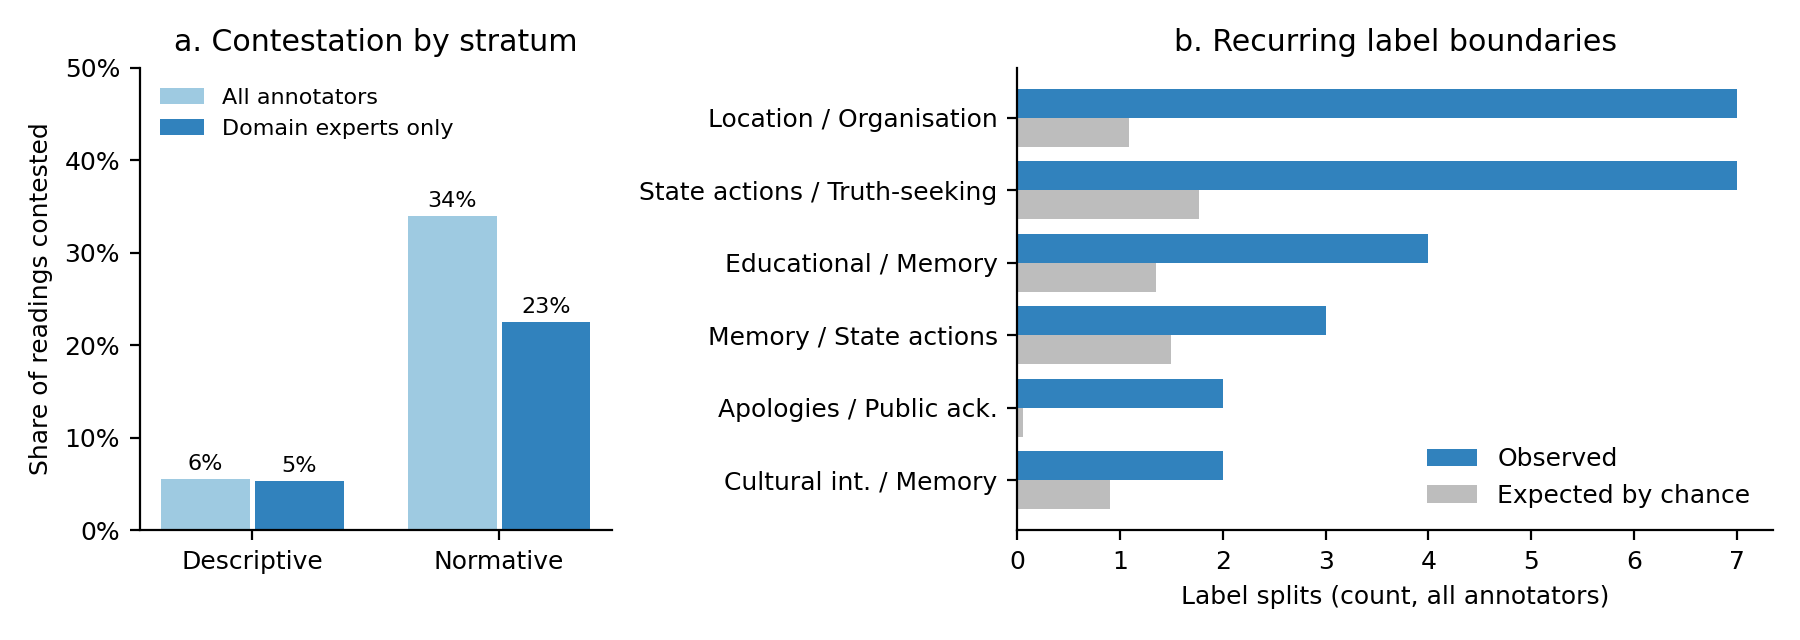

In [14]:
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
SHORT = {'State, executive and legislative actions': 'State actions', 'Public acknowledgements': 'Public ack.',
         'Memory and (re)signification': 'Memory', 'Educational tools/processes': 'Educational',
         'Truth-seeking initiatives': 'Truth-seeking', 'Cultural interventions': 'Cultural int.',
         'Contestation/mobilisation': 'Contestation', 'Policy or institutional reforms': 'Policy reforms',
         'Decolonisation trajectory': 'Decolonisation', 'Commemorative events': 'Commemorative'}

fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={'width_ratios': [1, 1.6]})
for k, (tag, sub) in enumerate([('All annotators', df), ('Domain experts only', df[df.pair == 'expert-expert'])]):
    b = sub[sub.ftype.isin(['contested', 'agreed'])]
    r = b.groupby('stratum').ftype.apply(lambda g: (g == 'contested').mean())
    bars = ax[0].bar(np.arange(2) + k * 0.38, [r['descriptive'], r['normative']], 0.36, label=tag,
                     color=['#9ecae1', '#3182bd'][k])
    for bar, v in zip(bars, [r['descriptive'], r['normative']]):
        ax[0].text(bar.get_x() + bar.get_width() / 2, v + .005, f'{v:.0%}', ha='center', va='bottom', fontsize=8)
ax[0].set_xticks(np.arange(2) + 0.19, ['Descriptive', 'Normative'])
ax[0].set_ylabel('Share of readings contested')
ax[0].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1, decimals=0))
ax[0].legend(frameon=False, loc='upper left', fontsize=8)
ax[0].set_ylim(0, .5)
ax[0].set_title('a. Contestation by stratum')

sp = df[df.other_label.notna() & (df.label != df.other_label) & df['first']]
keys = pd.Series([' / '.join(sorted(p)) for p in zip(sp.label, sp.other_label)])
p = pd.concat([sp.label, sp.other_label]).value_counts(normalize=True)
denom = 1 - (p ** 2).sum()
top = keys.value_counts().head(6)
exp = [len(sp) * 2 * p[a] * p[b] / denom for a, b in (k.split(' / ') for k in top.index)]
short = lambda s: ' / '.join(SHORT.get(x, x) for x in s.split(' / '))
y = np.arange(len(top))[::-1]
ax[1].barh(y + 0.2, top.values, 0.4, color='#3182bd', label='Observed')
ax[1].barh(y - 0.2, exp, 0.4, color='#bdbdbd', label='Expected by chance')
ax[1].set_yticks(y, [short(k) for k in top.index])
ax[1].set_xlabel('Label splits (count, all annotators)')
ax[1].legend(frameon=False, loc='lower right')
ax[1].set_title('b. Recurring label boundaries')
fig.tight_layout()
path = os.path.join(FIG_DIR, 'fig1_sq1_contestation.png')
fig.savefig(path, dpi=200)
plt.close(fig)
display(Image(filename=path))

## Step 7 — Recap: where each number appears in the paper

| Paper | Number | Step |
|---|---|---|
| §2.1 | duplicate article left out: 67 distinct texts | 0 |
| Table 1 | 67 texts (18 EN, 20 FR, 29 NL); 1,472 spans; 930 / 542; hesitant 6% / 16% / 11% | 1 |
| Table 1 | contested normative readings 41/182 (23%), 83/183 (45%), 124/365 (34%); 28 / 54 / 82 passages | 1 |
| §2.1 | retrospective ratings: 352 spans, hesitant 15% vs. 10% | 1 |
| §3.1, check 1 | 34% vs. 6% (experts 23% vs. 5%); hesitancy only 17% vs. 2%; per label 14% (Knowledge Forums) to 83% (State actions), Location 16% | 2 |
| §3.1, check 2 | HHI .091 vs. .047, about 11 vs. 21 pairs; experts .190 vs. .095 (p = .001, about 5 vs. 11 pairs); normative only 29 splits, .118 vs. .072 (p = .007, about 8 vs. 14 pairs); experts 9 splits, .210 vs. .151, n.s. | 3 |
| §3.1, check 3 | 8 of 21 (38%); naive 5%; stricter 12%, exact p < .001, binomial p = .003; experts 2 of 7 | 4 |
| §3.1, check 4 | 23% vs. 7% (experts 25% vs. 6%); OR 1.77 [1.15, 2.71] experts, 1.38 [0.99, 1.91] (p = .06) all annotators; variants 1.36–1.43 | 5 |
| Figure *Contestation by stratum* | panels (a) and (b) | 6 |